# Phase 4: Rent model

Run `python -m src.phase4` first. This notebook reads its outputs (MLflow runs, the registered model and the saved test predictions) and makes the charts. Nothing is retrained here.

In [1]:
import os
import sys
sys.path.append('..')
os.environ['MLFLOW_DISABLE_AGENT_HINT'] = '1'

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

from src.config import DATA_PROCESSED, MLFLOW_EXPERIMENT, MLFLOW_TRACKING_URI
from src.model_features import FEATURES
from src.plots import AQUA, BLUE, MUTED, ORANGE, save, use_style

use_style()
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
runs = mlflow.search_runs(experiment_names=[MLFLOW_EXPERIMENT])
pred = pd.read_parquet(DATA_PROCESSED / 'phase4_test_predictions.parquet')
MODELS = {'baseline': MUTED, 'ridge': ORANGE, 'xgboost': BLUE}
len(runs), len(pred)

/opt/anaconda3/envs/deal-analyzer/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(115, 758)

## 1. Optuna search
Each dot is one XGBoost setting, scored by spatial CV MAE on the training set. The line is the best score found so far.

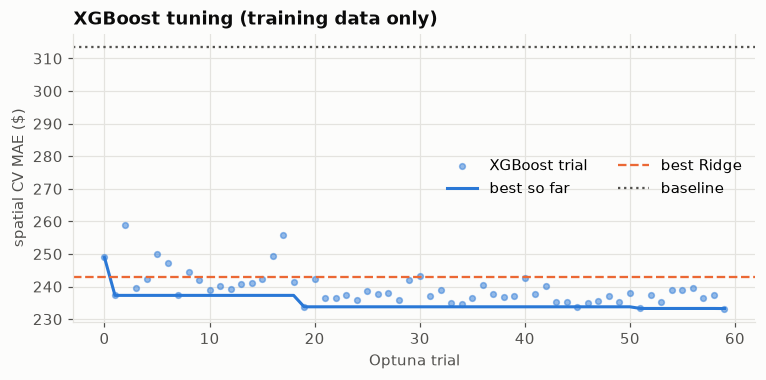

In [2]:
trials = runs[runs['tags.mlflow.runName'].str.startswith('xgb_trial_', na=False)].copy()
trials['trial'] = trials['tags.mlflow.runName'].str.replace('xgb_trial_', '').astype(int)
trials = trials.sort_values('trial')
ridge = runs[runs['tags.mlflow.runName'].str.startswith('ridge_a', na=False)]
base_cv = runs.loc[runs['tags.mlflow.runName'] == 'baseline_zip_beds_median', 'metrics.cv_spatial_mae'].iloc[0]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.scatter(trials['trial'], trials['metrics.cv_mae'], s=14, color=BLUE, alpha=0.5, label='XGBoost trial')
ax.plot(trials['trial'], trials['metrics.cv_mae'].cummin(), color=BLUE, label='best so far')
ax.axhline(ridge['metrics.cv_mae'].min(), color=ORANGE, linestyle='--', linewidth=1.5, label='best Ridge')
ax.axhline(base_cv, color=MUTED, linestyle=':', linewidth=1.5, label='baseline')
ax.set_xlabel('Optuna trial')
ax.set_ylabel('spatial CV MAE ($)')
ax.set_title('XGBoost tuning (training data only)')
ax.legend(ncol=2)
save(fig, 'phase4_optuna')

## 2. Test set: predicted vs actual

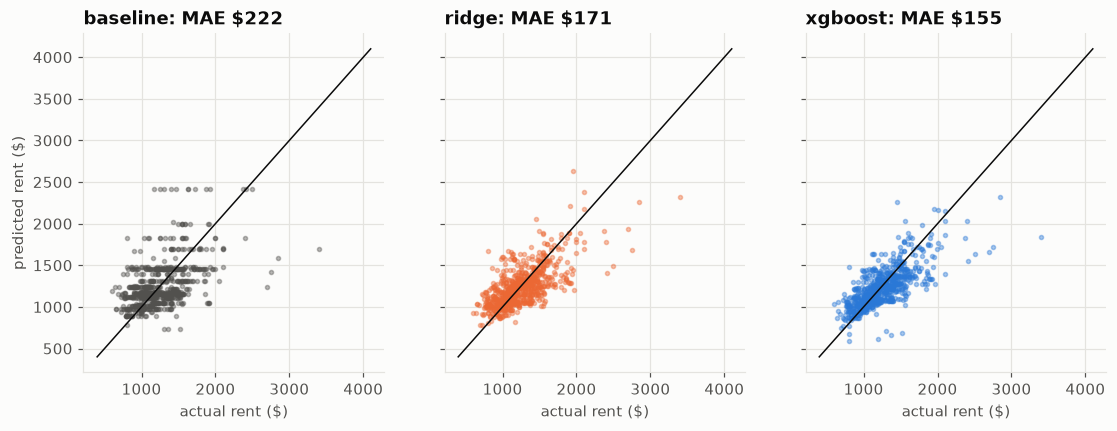

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
lim = [400, 4100]
for ax, (m, color) in zip(axes, MODELS.items()):
    mae = (pred[m] - pred['rent']).abs().mean()
    ax.scatter(pred['rent'], pred[m], s=7, alpha=0.4, color=color)
    ax.plot(lim, lim, color='#0b0b0b', linewidth=1)
    ax.set_title(f'{m}: MAE ${mae:.0f}')
    ax.set_xlabel('actual rent ($)')
axes[0].set_ylabel('predicted rent ($)')
save(fig, 'phase4_pred_vs_actual')

## 3. Error by region and price band

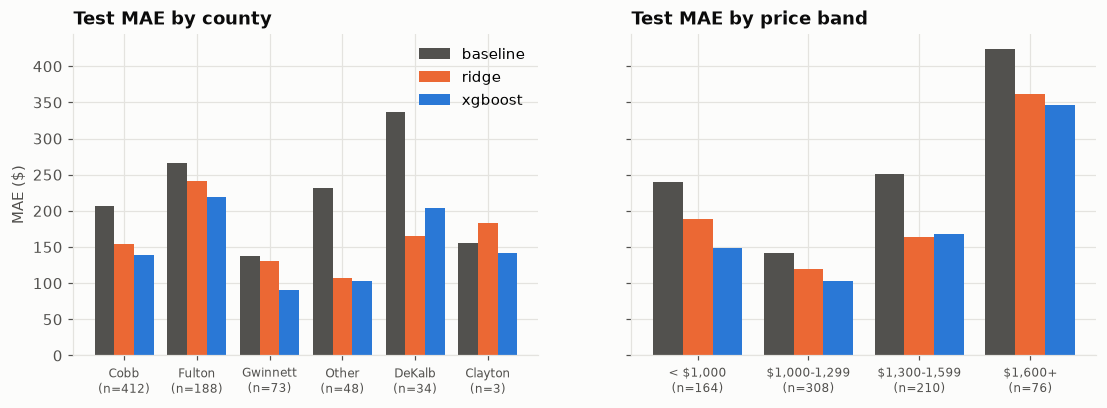

In [4]:
def mae_by(col):
    return pred.groupby(col, observed=True).apply(
        lambda g: pd.Series({m: (g[m] - g['rent']).abs().mean() for m in MODELS} | {'n': len(g)}),
        include_groups=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col in zip(axes, ['county', 'price_band']):
    t = mae_by(col)
    if col == 'county':
        t = t.sort_values('n', ascending=False)
    x = np.arange(len(t))
    for i, (m, color) in enumerate(MODELS.items()):
        ax.bar(x + (i - 1) * 0.27, t[m], 0.27, color=color, label=m)
    ax.set_xticks(x, [f'{g}\n(n={int(n)})' for g, n in zip(t.index, t['n'])], fontsize=8)
    ax.set_title(f'Test MAE by {col.replace("_", " ")}')
axes[0].set_ylabel('MAE ($)')
axes[0].legend()
save(fig, 'phase4_mae_breakdown')

## 4. What the model relies on
Left: CV MAE increase when a whole feature group is removed (ablation). Right: XGBoost's own importance (total gain) for the top features.

square_feet         0.112
nbr_log_rent_psf    0.108
zori                0.073
bathrooms           0.073
log_sqft            0.062
km_to_downtown      0.059
hud_safmr           0.056
zip_median_rent     0.050
dtype: float64

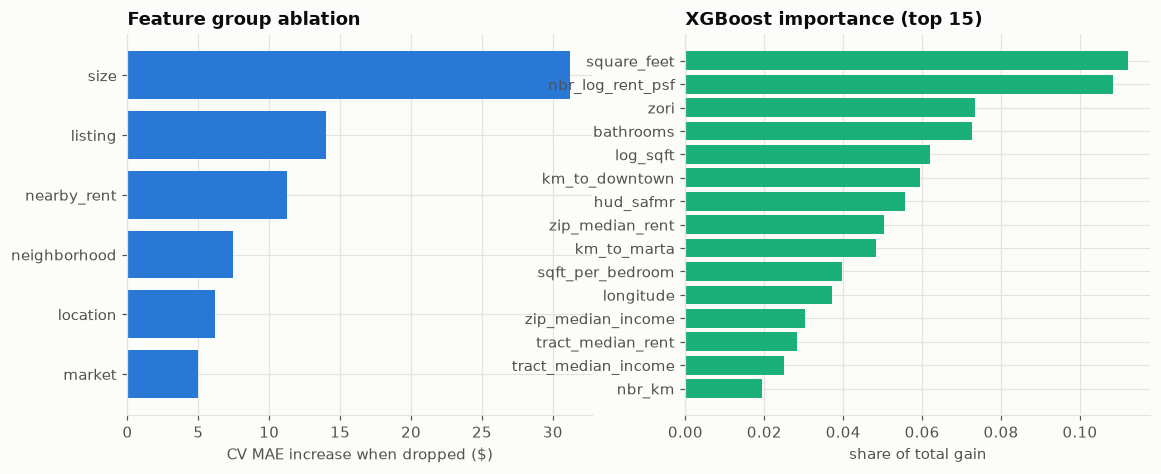

In [5]:
abl = runs[runs['tags.mlflow.runName'].str.startswith('drop_', na=False)].copy()
abl['group'] = abl['params.dropped_group']
full = abl.loc[abl['group'] == 'none (all features)', 'metrics.cv_mae'].iloc[0]
abl = abl[abl['group'] != 'none (all features)'].assign(change=lambda d: d['metrics.cv_mae'] - full).sort_values('change')

model = mlflow.sklearn.load_model('models:/rent-model/latest')
booster = model.regressor_.named_steps['model'].get_booster()
gain = pd.Series(booster.get_score(importance_type='total_gain'))
gain.index = [FEATURES[int(f[1:])] if f.startswith('f') and f[1:].isdigit() else f for f in gain.index]
gain = (gain / gain.sum()).sort_values().tail(15)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(abl['group'], abl['change'], color=BLUE)
axes[0].set_xlabel('CV MAE increase when dropped ($)')
axes[0].set_title('Feature group ablation')
axes[1].barh(gain.index, gain.values, color=AQUA)
axes[1].set_xlabel('share of total gain')
axes[1].set_title('XGBoost importance (top 15)')
save(fig, 'phase4_feature_importance')
gain.sort_values(ascending=False).round(3).head(8)

## 5. Summary

- **Spatial CV (training data):** baseline \$314 → Ridge \$243 → XGBoost **\$233**. XGBoost won on CV, so it is the registered model (`rent-model` in MLflow). The test set played no part in the choice.
- **Test set (opened once):** baseline \$222 → Ridge \$171 → XGBoost **\$155** MAE (MAPE 12.4%). That is **30.1% below the baseline** (95% paired bootstrap CI 25.3% to 34.7%), so the 20% target is met even at the low end of the interval.
- **By region:** XGBoost beats the baseline in every county. Fulton (in-town, \$219) is hardest. Cobb (\$139, the biggest test group) and Gwinnett (\$90) are easiest. DeKalb (n=34) and Clayton (n=3) are too small to rank.
- **By price band:** every model pulls toward the middle. It overpredicts cheap units (XGBoost +\$109 median vs +\$203 for the baseline) and underpredicts \$1,600+ units (about -\$300). Overall bias is close to zero (+\$1). The expensive end is the weak spot.
- **What matters:** size features matter most. Dropping them raises CV MAE by \$31. Next come listing details (amenities, photo; +\$14) and the nearby-rent feature (+\$11). Census neighborhood stats, location and market each add \$5-8. Rent depends mostly on the unit itself, then on what nearby units charge.
- **Tuning:** Optuna stopped improving after about 20 of 60 trials. Ridge needed heavy regularization (alpha = 1000) because many features overlap.